# Annex II revision — old vs. corrected series

The Oct 27, 2026 update (commit `342919f`) corrected the EO 14257 Annex II exemptions and the
April 2025 dates. This notebook compares the published series before and after it.

- **Old** = the CSVs at commit `aa4e228`, the last commit before the correction.
- **Fixed** = the CSVs in the working tree.

What changed:
- Annex II matched on HS8 with all 1,039 subheadings.
- China's fentanyl duty and Brazil's 40% kept on Annex II goods.
- Apr 5–8, 2025 at the 10% baseline.
- China at 145% during the pause.
- Canada and Mexico are unchanged (on hold).

Rates from Feb 20, 2026 on did not move.

In [1]:
%matplotlib inline
import io, subprocess
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.linewidth': 2, 'axes.labelweight': 'bold', 'axes.titleweight': 'bold',
    'axes.titlesize': 18, 'axes.labelsize': 16,
    'xtick.labelsize': 12, 'ytick.labelsize': 12,
    'legend.frameon': False, 'legend.fontsize': 12,
    'grid.alpha': 0.3, 'grid.linestyle': '--', 'savefig.bbox': 'tight',
})
PALETTE = {'old': '#C8860D', 'fixed': 'darkblue', 'up': '#8B0000', 'down': 'darkgreen'}

OLD_COMMIT = "aa4e228"   # last commit before the Annex II correction
WINDOW = (pd.Timestamp("2025-01-01"), pd.Timestamp("2026-03-31"))


def at_commit(path, commit=OLD_COMMIT):
    """Read a CSV as it was at a given commit."""
    out = subprocess.run(["git", "show", f"{commit}:{path}"],
                         capture_output=True, text=True, check=True).stdout
    return pd.read_csv(io.StringIO(out))


daily = (at_commit("daily-tariff-latest-data.csv")[["date", "import_weighted_avg_tariff"]]
         .merge(pd.read_csv("daily-tariff-latest-data.csv")[["date", "import_weighted_avg_tariff"]],
                on="date", suffixes=("_old", "_fixed")))
daily["date"] = pd.to_datetime(daily["date"])
daily = daily.set_index("date").rename(columns=lambda c: c.split("_")[-1])
daily["diff"] = daily["fixed"] - daily["old"]

panel_old = at_commit("country-by-time.csv")
panel_fixed = pd.read_csv("country-by-time.csv")
for p in (panel_old, panel_fixed):
    p["date"] = pd.to_datetime(p["date"])
print("daily rows:", len(daily), " panel dates old/fixed:",
      panel_old.date.nunique(), panel_fixed.date.nunique())

daily rows: 724  panel dates old/fixed: 25 25


## 1. The national average

The top panel shows the levels and the bottom panel shows fixed minus old, in percentage points.
The shaded band is Apr 5–8, 2025, the 10% baseline correction.

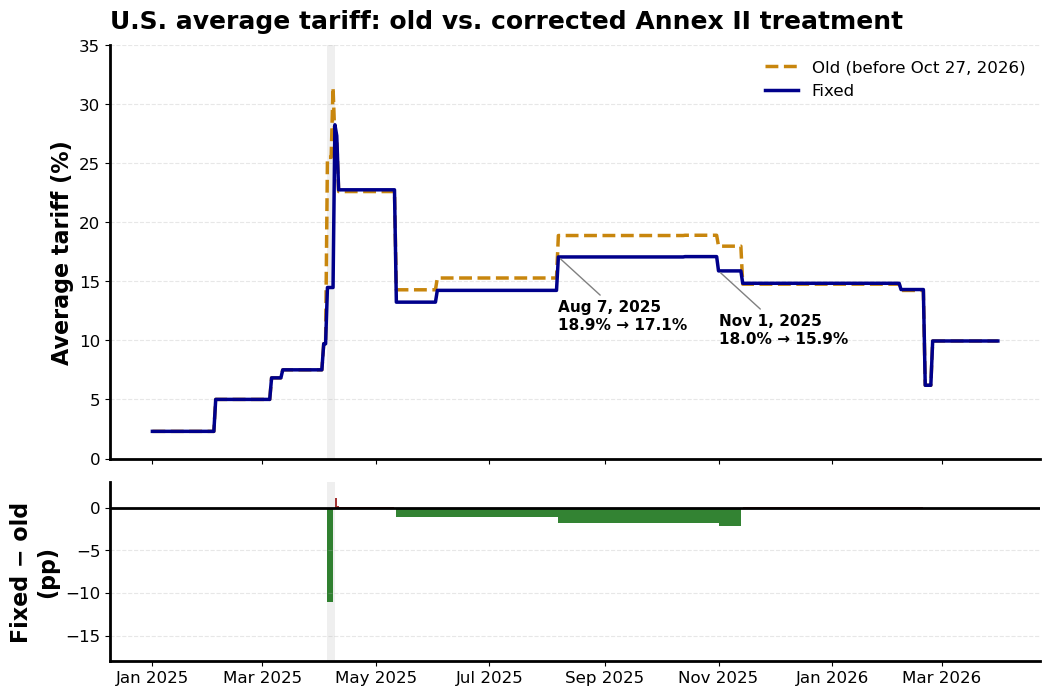

,old,fixed,diff
date,,,
2025-04-05,25.51,14.48,-11.02
2025-04-09,27.10,28.27,1.17
2025-04-10,27.10,27.33,0.24
2025-04-11,22.61,22.76,0.15
2025-05-12,14.29,13.24,-1.05
2025-08-07,18.89,17.07,-1.81
2025-11-01,17.98,15.89,-2.09
2025-11-14,14.77,14.84,0.07
2026-02-07,14.24,14.31,0.07


In [2]:
d = daily.loc[WINDOW[0]:WINDOW[1]]

fig, (ax, axd) = plt.subplots(2, 1, figsize=(12, 8), sharex=True,
                              gridspec_kw={'height_ratios': [3, 1.3], 'hspace': 0.08})
ax.plot(d.index, d["old"], color=PALETTE['old'], lw=2.5, ls='--', label='Old (before Oct 27, 2026)')
ax.plot(d.index, d["fixed"], color=PALETTE['fixed'], lw=2.5, label='Fixed')
for a in (ax, axd):
    a.axvspan(pd.Timestamp("2025-04-05"), pd.Timestamp("2025-04-09"), color='gray', alpha=0.12, lw=0)
ax.set_ylabel("Average tariff (%)")
ax.set_ylim(0, 35)
ax.grid(axis='y')
ax.legend(loc='upper right')
ax.set_title("U.S. average tariff: old vs. corrected Annex II treatment", loc='left', pad=12)

for label, x in [("Aug 7, 2025", "2025-08-07"), ("Nov 1, 2025", "2025-11-01")]:
    r = daily.loc[x]
    ax.annotate(f"{label}\n{r['old']:.1f}% → {r['fixed']:.1f}%", xy=(pd.Timestamp(x), r['fixed']),
                xytext=(0, -52), textcoords='offset points', ha='left', fontsize=11,
                fontweight='bold', color='black',
                arrowprops=dict(arrowstyle='-', color='gray', lw=1))

axd.fill_between(d.index, d["diff"], 0, where=d["diff"] < 0, color=PALETTE['down'], alpha=0.8,
                 step='post', lw=0)
axd.fill_between(d.index, d["diff"], 0, where=d["diff"] > 0, color=PALETTE['up'], alpha=0.8,
                 step='post', lw=0)
axd.axhline(0, color='black', lw=2)
axd.set_ylabel("Fixed − old\n(pp)")
axd.set_ylim(-18, 3)
axd.grid(axis='y')
axd.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

fig.savefig("figures/annex-ii-revision-national.png")
plt.show()

steps = ["2025-04-05", "2025-04-09", "2025-04-10", "2025-04-11", "2025-05-12", "2025-08-07",
         "2025-11-01", "2025-11-14", "2026-02-07", "2026-02-20"]
daily.loc[steps, ["old", "fixed", "diff"]].round(2)

## 2. Which countries it mattered for

The change on **Aug 7, 2025** is the middle of the Annex II window and is clear of the April date
fix. The left panel is the change in each country's own rate. The right panel is that change
weighted by the country's share of 2024 imports, which is its contribution to the national
change.

national change on Aug 07, 2025: -1.81 pp


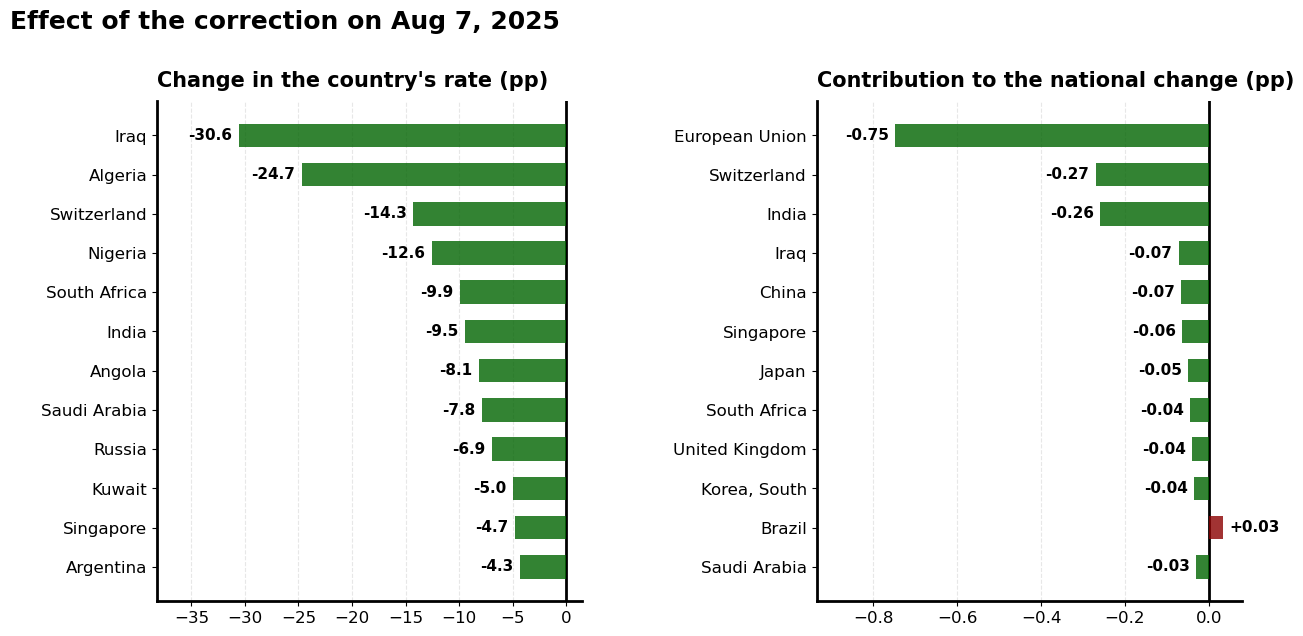

,old,fixed,pp,contrib
country_name,,,,
EUROPEAN UNION,15.20,11.17,-4.03,-0.75
SWITZERLAND,38.58,24.32,-14.26,-0.27
INDIA,43.03,33.56,-9.47,-0.26
IRAQ,31.33,0.75,-30.57,-0.07
CHINA,31.06,30.57,-0.49,-0.07
SINGAPORE,9.54,4.80,-4.74,-0.06
JAPAN,15.42,14.37,-1.05,-0.05
SOUTH AFRICA,28.28,18.38,-9.90,-0.04
UNITED KINGDOM,12.88,11.01,-1.87,-0.04


In [3]:
DATE = pd.Timestamp("2025-08-07")
x = (panel_old[panel_old.date == DATE].set_index("country_name")[["effective tariff", "total imports"]]
     .join(panel_fixed[panel_fixed.date == DATE].set_index("country_name")[["effective tariff"]],
           rsuffix="_fixed"))
x.columns = ["old", "imports", "fixed"]
x["pp"] = x["fixed"] - x["old"]
x["contrib"] = x["pp"] * x["imports"] / x["imports"].sum()
print(f"national change on {DATE:%b %d, %Y}: {x['contrib'].sum():+.2f} pp")

N = 12
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={'wspace': 0.55})
for a, col, title, fmt in [(a1, "pp", "Change in the country's rate (pp)", "{:+.1f}"),
                           (a2, "contrib", "Contribution to the national change (pp)", "{:+.2f}")]:
    top = x.reindex(x[col].abs().sort_values(ascending=False).index).head(N).iloc[::-1]
    colors = [PALETTE['down'] if v < 0 else PALETTE['up'] for v in top[col]]
    bars = a.barh(top.index.str.title(), top[col], height=0.6, color=colors, alpha=0.8, zorder=3)
    a.axvline(0, color='black', lw=2)
    a.grid(axis='x')
    a.set_title(title, loc='left', pad=10, fontsize=15)
    span = top[col].abs().max()
    for b, v in zip(bars, top[col]):
        a.text(v + (0.02 * span if v >= 0 else -0.02 * span), b.get_y() + b.get_height() / 2,
               fmt.format(v), va='center', ha='left' if v >= 0 else 'right',
               fontsize=11, fontweight='bold', color='black')
    a.set_xlim(min(top[col].min(), 0) * 1.25, max(top[col].max(), 0) * 1.25 + 0.05 * span)
fig.suptitle(f"Effect of the correction on {DATE:%b} {DATE.day}, {DATE.year}", x=0.02, ha='left',
             fontsize=18, fontweight='bold', y=1.02)
fig.savefig("figures/annex-ii-revision-countries.png")
plt.show()

x.sort_values("contrib")[["old", "fixed", "pp", "contrib"]].head(10).round(2)

## 3. Old vs. fixed paths for the countries it mattered most for

These are the panel's policy dates, drawn as steps. Each series is the country's tariff
increase since January 2025, which excludes the 2.3% MFN baseline that the national series
adds.

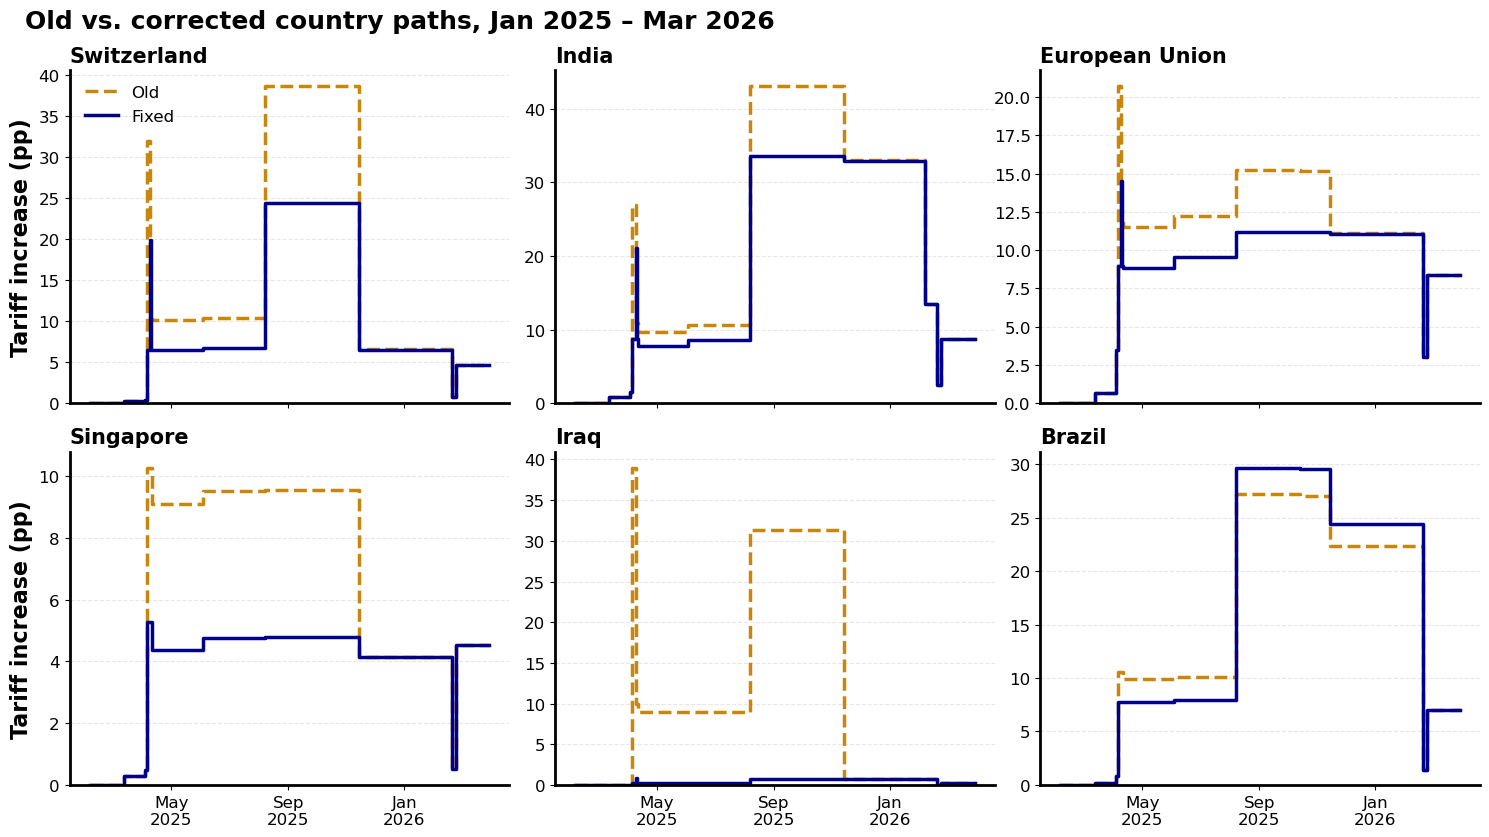

In [4]:
SHOW = ["SWITZERLAND", "INDIA", "EUROPEAN UNION", "SINGAPORE", "IRAQ", "BRAZIL"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), sharex=True)
for a, name in zip(axes.flat, SHOW):
    for p, key, ls in [(panel_old, 'old', '--'), (panel_fixed, 'fixed', '-')]:
        s = p[p.country_name == name].set_index("date")["effective tariff"].sort_index()
        s = s[s.index <= WINDOW[1]]
        s.loc[WINDOW[1]] = s.iloc[-1]          # carry the last step to the window edge
        a.step(s.index, s.values, where='post', color=PALETTE[key], lw=2.5, ls=ls,
               label='Old' if key == 'old' else 'Fixed')
    a.set_title(name.title(), loc='left', fontsize=15)
    a.set_ylim(bottom=0)
    a.grid(axis='y')
    a.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 5, 9]))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
axes.flat[0].legend(loc='upper left')
for a in axes[:, 0]:
    a.set_ylabel("Tariff increase (pp)")
fig.suptitle("Old vs. corrected country paths, Jan 2025 – Mar 2026", x=0.02, ha='left',
             fontsize=18, fontweight='bold')
fig.tight_layout()
fig.savefig("figures/annex-ii-revision-country-paths.png")
plt.show()